# 🛠️ **IMPORTS**: Bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 💻 **CÓDIGOS**: Implementação

In [2]:
file_mun = "../data/dtb/RELATORIO_DTB_BRASIL_2024_MUNICIPIOS.xlsx"
file_dist = "../data/dtb/RELATORIO_DTB_BRASIL_2024_DISTRITOS.xlsx"
file_subdist = "../data/dtb/RELATORIO_DTB_BRASIL_2024_SUBDISTRITOS.xlsx"
file_censo = '../data/censo2022/br_ibge_censo_2022_municipio.xlsx'

df_mun = pd.read_excel(file_mun)
df_dist = pd.read_excel(file_dist)
df_subdist = pd.read_excel(file_subdist)
df_censo = pd.read_excel(file_censo)
print("Arquivos carregados com sucesso.")

Arquivos carregados com sucesso.


In [3]:
df_mun_clean = df_mun[['Código Município Completo', 'Nome_Município', 'Nome_UF']].copy()
df_mun_clean.rename(columns={
    'Código Município Completo': 'id_municipio',
    'Nome_Município': 'nome_municipio',
    'Nome_UF': 'nome_uf'
}, inplace=True)
df_mun_clean.drop_duplicates(subset=['id_municipio'], inplace=True)

df_mun_clean.to_csv('../data/dtb/tabela_municipios.csv', index=False, encoding='utf-8')

df_dist_clean = df_dist[['Código Município Completo', 'Código de Distrito Completo', 'Nome_Distrito']].copy()
df_dist_clean.rename(columns={
    'Código Município Completo': 'id_municipio',
    'Código de Distrito Completo': 'id_distrito',
    'Nome_Distrito': 'nome_distrito'
}, inplace=True)

df_mun_dist = pd.merge(
    df_dist_clean,
    df_mun_clean,
    on='id_municipio',
    how='left'
)

df_mun_dist = df_mun_dist[[
    'id_municipio', 'nome_municipio', 'nome_uf', 
    'id_distrito', 'nome_distrito'
]]

df_mun_dist.to_csv('../data/dtb/tabela_municipios_distritos.csv', index=False, encoding='utf-8')

In [4]:
df_mun = pd.read_csv('../data/dtb/tabela_municipios.csv')

In [5]:
uf_para_regiao = {
    'Rondônia': 'Norte', 'Acre': 'Norte', 'Amazonas': 'Norte', 
    'Roraima': 'Norte', 'Pará': 'Norte', 'Amapá': 'Norte', 
    'Tocantins': 'Norte',
    
    'Maranhão': 'Nordeste', 'Piauí': 'Nordeste', 'Ceará': 'Nordeste', 
    'Rio Grande do Norte': 'Nordeste', 'Paraíba': 'Nordeste', 'Pernambuco': 'Nordeste', 
    'Alagoas': 'Nordeste', 'Sergipe': 'Nordeste', 'Bahia': 'Nordeste',
    
    'Minas Gerais': 'Sudeste', 'Espírito Santo': 'Sudeste', 'Rio de Janeiro': 'Sudeste', 
    'São Paulo': 'Sudeste',
    
    'Paraná': 'Sul', 'Santa Catarina': 'Sul', 'Rio Grande do Sul': 'Sul',
    
    'Mato Grosso do Sul': 'Centro-Oeste', 'Mato Grosso': 'Centro-Oeste', 
    'Goiás': 'Centro-Oeste', 'Distrito Federal': 'Centro-Oeste'
}

In [6]:
# 3.1. Seleção e Renomeação Censo
df_censo_clean = df_censo[['id_municipio', 'taxa_alfabetizacao']].copy()

# 3.2. Seleção e Renomeação Municípios (para UF)
df_mun_clean = df_mun[['id_municipio', 'nome_uf']].copy()

# Merge para associar a taxa de alfabetização à UF do município
df_final = pd.merge(
    df_censo_clean,
    df_mun_clean,
    on='id_municipio',
    how='inner'
)

# 3.3. Criar a coluna 'Grande_Regiao' usando o mapeamento
df_final['Grande_Regiao'] = df_final['nome_uf'].map(uf_para_regiao)

# Limpeza e conversão de tipo
df_final['taxa_alfabetizacao'] = pd.to_numeric(df_final['taxa_alfabetizacao'], errors='coerce')
df_final.dropna(subset=['taxa_alfabetizacao', 'Grande_Regiao'], inplace=True)

In [7]:
# Requisito: group by
df_regiao_alfabetizacao = (
    df_final.groupby('Grande_Regiao')['taxa_alfabetizacao']
    .mean()
    .reset_index()
)
df_regiao_alfabetizacao.columns = ['Grande_Regiao', 'Taxa_Media_Alfabetizacao']

# Ordenar o resultado
df_regiao_alfabetizacao_sorted = df_regiao_alfabetizacao.sort_values(
    by='Taxa_Media_Alfabetizacao', 
    ascending=False
)

print("\n--- Taxa Média de Alfabetização por Grande Região ---")
print(df_regiao_alfabetizacao_sorted)


--- Taxa Média de Alfabetização por Grande Região ---
  Grande_Regiao  Taxa_Media_Alfabetizacao
4           Sul                  0.944192
3       Sudeste                  0.923679
0  Centro-Oeste                  0.911771
2         Norte                  0.877076
1      Nordeste                  0.795437


# 🏙️ Gráfico: Taxa Média de Alfabetização por Grande Região (Censo 2022)

**Este gráfico de barras** apresenta a taxa média de alfabetização para as cinco Grandes Regiões do Brasil (Norte, Nordeste, Sudeste, Sul e Centro-Oeste), com base nos dados municipais do Censo 2022.

---

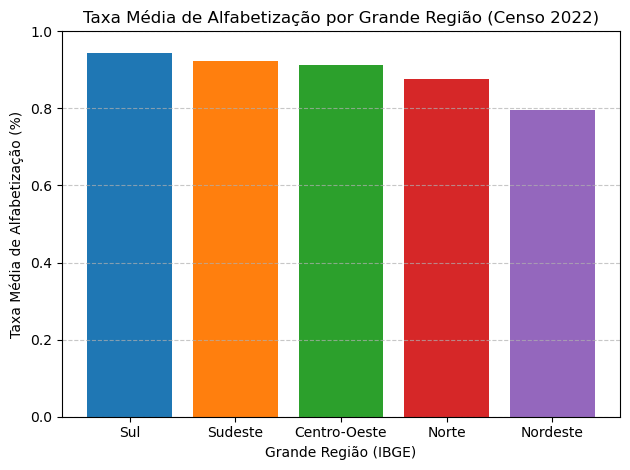

In [8]:
plt.figure(1)
plt.clf()

plt.bar(
    df_regiao_alfabetizacao_sorted['Grande_Regiao'], 
    df_regiao_alfabetizacao_sorted['Taxa_Media_Alfabetizacao'],
    color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
)

plt.title('Taxa Média de Alfabetização por Grande Região (Censo 2022)')
plt.xlabel('Grande Região (IBGE)')
plt.ylabel('Taxa Média de Alfabetização (%)')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()